## <span style="color:#1F4E79;">Optimization of the Bradley–Terry Likelihood</span>

This notebook compares different methods for fitting the Bradley–Terry model. We first use handcrafted optimizers and then reproduce the experiments using PyTorch. Every method is tested on the same simulated dataset.

In [15]:
# Import numerical, tabular, plotting and Bradley–Terry utilities.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from bradley_terry import *

##### Reusable Bradley–Terry Functions

| Function | Purpose |
|---|---|
| `center_parameters()` | Centres the parameters so that their mean is zero. |
| `generate_uniform_comparison_data()` | Simulates `(winner, loser)` observations. |
| `average_negative_log_likelihood()` | Calculates the average NLL on the complete dataset. |
| `parameter_recovery_error()` | Calculates RMSE between the true and estimated parameters. |
| `ford_condition_holds()` | Checks whether a finite Bradley–Terry MLE exists. |
| `optimize_with_full_batch_gradient_descent()` | Updates the parameters using the complete dataset. |
| `optimize_with_stochastic_gradient_descent()` | Updates the parameters using one observation at a time. |
| `optimize_with_minibatch_gradient_descent()` | Updates the parameters using small batches of observations. |
| `optimize_with_momentum_gradient_descent()` | Applies momentum to mini-batch gradient descent. |
| `optimize_with_adam()` | Uses Adam's adaptive first- and second-moment updates. |
| `OptimizationResult` | Stores the fitted parameters, optimization history and runtime. |

In [16]:
# Define settings shared by every optimizer.

SEED = 20260831
NUMBER_OF_ITEMS = 10
NUMBER_OF_COMPARISONS = 10_000
MINIBATCH_SIZE = 128
GRADIENT_TOLERANCE = 1e-6

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)

experiment_settings = pd.DataFrame({
    "Setting": [
        "Random seed",
        "Number of items",
        "Number of comparisons",
        "Mini-batch size",
        "Full-gradient tolerance",
    ],
    "Value": [
        str(SEED),
        str(NUMBER_OF_ITEMS),
        f"{NUMBER_OF_COMPARISONS:,}",
        str(MINIBATCH_SIZE),
        f"{GRADIENT_TOLERANCE:.1e}",
    ],
})

experiment_settings

,Setting,Value
0,Random seed,20260831
1,Number of items,10
2,Number of comparisons,"10,000"
3,Mini-batch size,128
4,Full-gradient tolerance,1.0e-06


### Common Dataset
We generate one Bradley–Terry dataset and keep it fixed throughout the notebook. Every optimizer therefore receives the same observations and starts from the same zero parameter vector.

In [17]:
# Generate one fixed dataset for all optimization experiments.

item_names = [
    f"Item {item_index}"
    for item_index in range(NUMBER_OF_ITEMS)
]

true_parameters = center_parameters(
    rng.normal(
        loc=0.0,
        scale=0.8,
        size=NUMBER_OF_ITEMS,
    )
)

comparisons = generate_uniform_comparison_data(
    true_parameters=true_parameters,
    number_of_comparisons=NUMBER_OF_COMPARISONS,
    rng=rng,
)

true_parameter_table = pd.DataFrame({
    "Item": item_names,
    "True parameter": true_parameters,
})

print(f"Number of observations: {len(comparisons):,}")
print(f"First five observations: {comparisons[:5]}")
print(
    "Ford's condition holds:",
    ford_condition_holds(
        NUMBER_OF_ITEMS,
        comparisons,
    ),
)

true_parameter_table.style.format({
    "True parameter": "{:.4f}",
})

Number of observations: 10,000
First five observations: [(1, 4), (8, 9), (0, 8), (0, 4), (3, 7)]
Ford's condition holds: True


,Item,True parameter
0,Item 0,0.0499
1,Item 1,0.0969
2,Item 2,0.4827
3,Item 3,1.5604
4,Item 4,-0.3540
5,Item 5,-1.1734
6,Item 6,-0.1724
7,Item 7,0.0065
8,Item 8,-0.5966
9,Item 9,0.0999


In [4]:
# Summarize item appearances and verify Ford's condition.

comparison_array = np.asarray(
    comparisons,
    dtype=int,
)

wins = np.bincount(
    comparison_array[:, 0],
    minlength=NUMBER_OF_ITEMS,
)

losses = np.bincount(
    comparison_array[:, 1],
    minlength=NUMBER_OF_ITEMS,
)

appearances = wins + losses
empirical_win_rates = wins / appearances

comparison_summary_table = pd.DataFrame({
    "item": item_names,
    "true_parameter": true_parameters,
    "wins": wins,
    "losses": losses,
    "appearances": appearances,
    "empirical_win_rate": empirical_win_rates,
})

print(
    "Ford's condition holds:",
    ford_condition_holds(
        NUMBER_OF_ITEMS,
        comparisons,
    ),
)

comparison_summary_table

Ford's condition holds: True


,item,true_parameter,wins,losses,appearances,empirical_win_rate
0,Item 0,0.04995,1033,958,1991,0.51883
1,Item 1,0.09685,1028,927,1955,0.52583
2,Item 2,0.48274,1267,793,2060,0.61505
3,Item 3,1.56037,1702,309,2011,0.84635
4,Item 4,-0.35400,838,1133,1971,0.42516
5,Item 5,-1.17337,467,1567,2034,0.22960
6,Item 6,-0.17237,869,1093,1962,0.44292
7,Item 7,0.00647,1038,934,1972,0.52637
8,Item 8,-0.59657,712,1309,2021,0.35230
9,Item 9,0.09993,1046,977,2023,0.51705


### Experiment 1: Handcrafted Full-Batch Gradient Descent

In [18]:
# Fit the model using convergence-driven handcrafted full-batch GD.

full_batch_learning_rate = 0.1

full_batch_result = optimize_with_full_batch_gradient_descent(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=full_batch_learning_rate,
    gradient_tolerance=GRADIENT_TOLERANCE,
)

full_batch_recovery_error = parameter_recovery_error(
    true_parameters,
    full_batch_result.parameters,
)

final_gradient_norm = float(
    full_batch_result.gradient_norm_history[-1]
)

full_batch_converged = (
    final_gradient_norm <= GRADIENT_TOLERANCE
)

full_batch_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Gradient tolerance",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Final gradient norm",
        "Converged",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{full_batch_learning_rate:.4f}",
        f"{GRADIENT_TOLERANCE:.4e}",
        f"{full_batch_result.nll_history[0]:.4f}",
        f"{full_batch_result.nll_history[-1]:.4f}",
        f"{full_batch_recovery_error:.4f}",
        f"{full_batch_result.epochs_completed:,}",
        f"{int(full_batch_result.update_count_history[-1]):,}",
        f"{final_gradient_norm:.4e}",
        str(full_batch_converged),
        full_batch_result.stopping_reason,
        f"{full_batch_result.runtime_seconds:.4f}",
        f"{full_batch_result.parameters.sum():.4e}",
    ],
})

full_batch_summary

,Quantity,Value
0,Learning rate,0.1000
1,Gradient tolerance,1.0000e-06
2,Initial NLL,0.6931
3,Final NLL,0.5982
4,Parameter-recovery RMSE,0.0383
5,Epochs completed,"3,706"
6,Parameter updates,"3,706"
7,Final gradient norm,9.9908e-07
8,Converged,True
9,Stopping reason,gradient tolerance reached


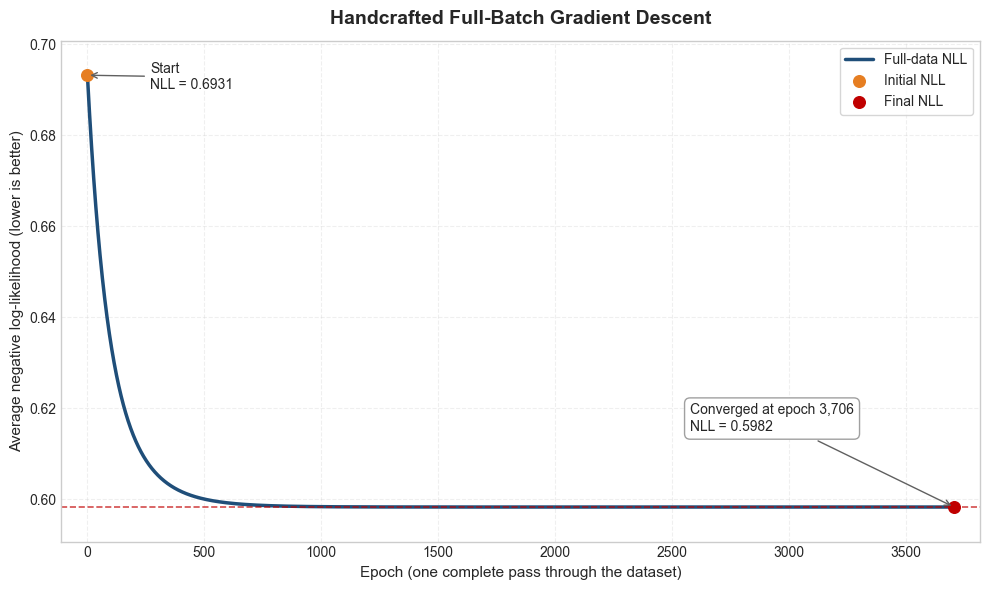

In [19]:
# Plot the full-data NLL during handcrafted full-batch optimization.

full_batch_nll_history = np.asarray(
    full_batch_result.nll_history,
    dtype=float,
)

full_batch_epochs = np.arange(
    len(full_batch_nll_history)
)

initial_nll = full_batch_nll_history[0]
final_nll = full_batch_nll_history[-1]
stopping_epoch = full_batch_result.epochs_completed

figure, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    full_batch_epochs,
    full_batch_nll_history,
    color="#1F4E79",
    linewidth=2.5,
    label="Full-data NLL",
)

axis.scatter(
    0,
    initial_nll,
    color="#E67E22",
    s=70,
    zorder=3,
    label="Initial NLL",
)

axis.scatter(
    stopping_epoch,
    final_nll,
    color="#C00000",
    s=70,
    zorder=3,
    label="Final NLL",
)

axis.axhline(
    final_nll,
    color="#C00000",
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
)

axis.annotate(
    f"Start\nNLL = {initial_nll:.4f}",
    xy=(0, initial_nll),
    xytext=(45, -10),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
)

axis.annotate(
    (
        f"Converged at epoch {stopping_epoch:,}\n"
        f"NLL = {final_nll:.4f}"
    ),
    xy=(stopping_epoch, final_nll),
    xytext=(-190, 55),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Average negative log-likelihood (lower is better)",
    fontsize=11,
)

axis.set_title(
    "Handcrafted Full-Batch Gradient Descent",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.03, y=0.08)

plt.tight_layout()
plt.show()

#### Convergence check
To show that the gradient norm is falling below the selected gradient tolerance and has converged.

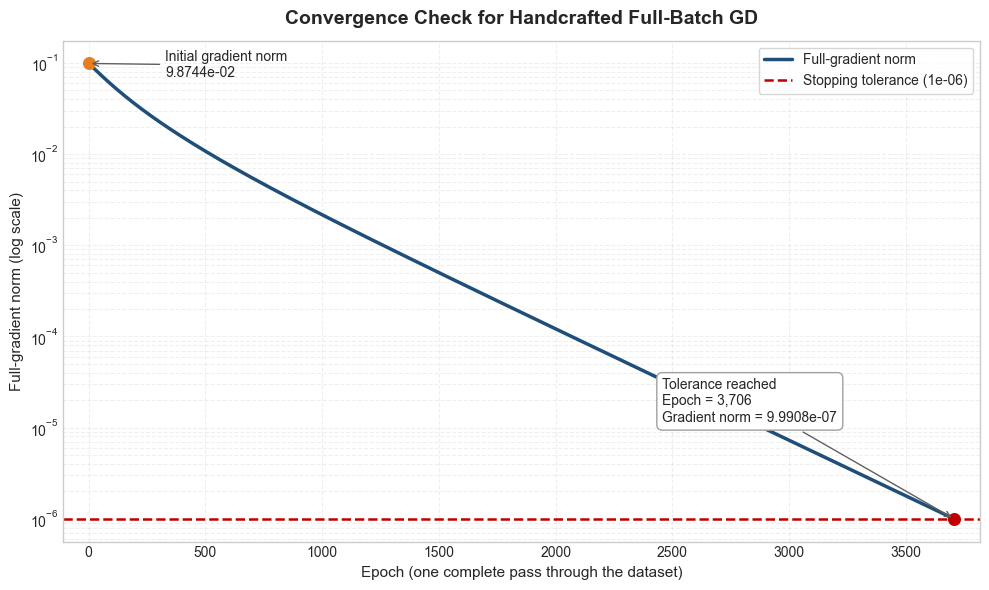

In [20]:
# Plot the full-gradient norm and the stopping tolerance.

gradient_norm_history = np.asarray(
    full_batch_result.gradient_norm_history,
    dtype=float,
)

gradient_epochs = np.arange(
    len(gradient_norm_history)
)

initial_gradient_norm = gradient_norm_history[0]
final_gradient_norm = gradient_norm_history[-1]
stopping_epoch = full_batch_result.epochs_completed

figure, axis = plt.subplots(figsize=(10, 6))

axis.semilogy(
    gradient_epochs,
    gradient_norm_history,
    color="#1F4E79",
    linewidth=2.5,
    label="Full-gradient norm",
)

axis.axhline(
    y=GRADIENT_TOLERANCE,
    color="#C00000",
    linestyle="--",
    linewidth=1.8,
    label=(
        "Stopping tolerance "
        f"({GRADIENT_TOLERANCE:.0e})"
    ),
)

axis.scatter(
    0,
    initial_gradient_norm,
    color="#E67E22",
    s=70,
    zorder=3,
)

axis.scatter(
    stopping_epoch,
    final_gradient_norm,
    color="#C00000",
    s=70,
    zorder=3,
)

axis.annotate(
    (
        f"Initial gradient norm\n"
        f"{initial_gradient_norm:.4e}"
    ),
    xy=(0, initial_gradient_norm),
    xytext=(55, -10),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
)

axis.annotate(
    (
        f"Tolerance reached\n"
        f"Epoch = {stopping_epoch:,}\n"
        f"Gradient norm = {final_gradient_norm:.4e}"
    ),
    xy=(stopping_epoch, final_gradient_norm),
    xytext=(-210, 70),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Full-gradient norm (log scale)",
    fontsize=11,
)

axis.set_title(
    "Convergence Check for Handcrafted Full-Batch GD",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.03)

plt.tight_layout()
plt.show()

### Experiment 2: Handcrafted Stochastic Gradient Descent


In [21]:
# Fit the model using convergence-driven handcrafted SGD.

sgd_learning_rate = 0.001
NLL_TARGET_MARGIN = 1e-4

reference_nll = float(
    full_batch_result.nll_history[-1]
)

target_nll = (
    reference_nll
    + NLL_TARGET_MARGIN
)

sgd_result = optimize_with_stochastic_gradient_descent(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=sgd_learning_rate,
    random_seed=SEED,
    target_nll=target_nll,
)

sgd_recovery_error = parameter_recovery_error(
    true_parameters,
    sgd_result.parameters,
)

sgd_final_nll = float(
    sgd_result.nll_history[-1]
)

sgd_target_reached = (
    sgd_final_nll <= target_nll
)

sgd_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Reference full-batch NLL",
        "Allowed NLL margin",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{sgd_learning_rate:.4f}",
        f"{reference_nll:.4f}",
        f"{NLL_TARGET_MARGIN:.4e}",
        f"{target_nll:.4f}",
        f"{sgd_result.nll_history[0]:.4f}",
        f"{sgd_final_nll:.4f}",
        f"{sgd_recovery_error:.4f}",
        f"{sgd_result.epochs_completed:,}",
        f"{int(sgd_result.update_count_history[-1]):,}",
        str(sgd_target_reached),
        sgd_result.stopping_reason,
        f"{sgd_result.runtime_seconds:.4f}",
        f"{sgd_result.parameters.sum():.4e}",
    ],
})

sgd_summary

,Quantity,Value
0,Learning rate,0.0010
1,Reference full-batch NLL,0.5982
2,Allowed NLL margin,1.0000e-04
3,Target NLL,0.5983
4,Initial NLL,0.6931
5,Final NLL,0.5983
6,Parameter-recovery RMSE,0.0440
7,Epochs completed,10
8,Parameter updates,"100,000"
9,Target reached,True


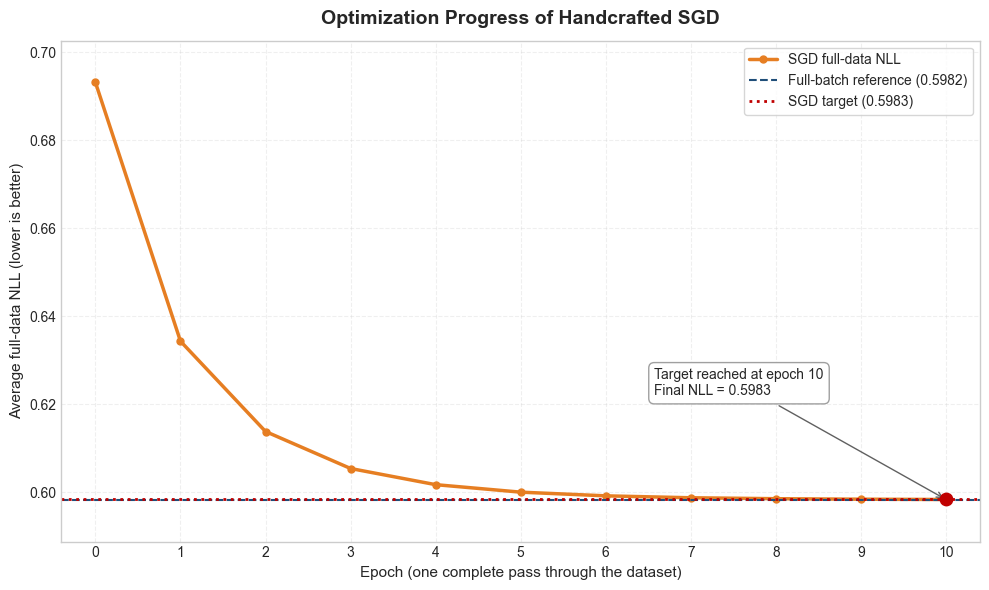

In [22]:
# Plot the full-data NLL during handcrafted SGD.

sgd_nll_history = np.asarray(
    sgd_result.nll_history,
    dtype=float,
)

sgd_epochs = np.arange(
    len(sgd_nll_history)
)

sgd_final_epoch = sgd_result.epochs_completed
sgd_final_nll = sgd_nll_history[-1]

figure, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    sgd_epochs,
    sgd_nll_history,
    color="#E67E22",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="SGD full-data NLL",
)

axis.axhline(
    y=reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.5,
    label=f"Full-batch reference ({reference_nll:.4f})",
)

axis.axhline(
    y=target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"SGD target ({target_nll:.4f})",
)

axis.scatter(
    sgd_final_epoch,
    sgd_final_nll,
    color="#C00000",
    s=80,
    zorder=4,
)

axis.annotate(
    (
        f"Target reached at epoch {sgd_final_epoch}\n"
        f"Final NLL = {sgd_final_nll:.4f}"
    ),
    xy=(sgd_final_epoch, sgd_final_nll),
    xytext=(-210, 75),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Average full-data NLL (lower is better)",
    fontsize=11,
)

axis.set_title(
    "Optimization Progress of Handcrafted SGD",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.set_xticks(sgd_epochs)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.04, y=0.1)

plt.tight_layout()
plt.show()

The full-data NLL is measured after every epoch. The dashed lines above shows the accurate full-batch result and the target that SGD must reach.



### Experiment 3: Handcrafted Mini-Batch Gradient Descent


In [23]:
# Fit the model using convergence-driven mini-batch gradient descent.

minibatch_learning_rate = 0.01

minibatch_result = optimize_with_minibatch_gradient_descent(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=minibatch_learning_rate,
    batch_size=MINIBATCH_SIZE,
    random_seed=SEED,
    target_nll=target_nll,
)

minibatch_recovery_error = parameter_recovery_error(
    true_parameters,
    minibatch_result.parameters,
)

minibatch_final_nll = float(
    minibatch_result.nll_history[-1]
)

minibatch_target_reached = (
    minibatch_final_nll <= target_nll
)

batches_per_epoch = int(
    np.ceil(
        NUMBER_OF_COMPARISONS
        / MINIBATCH_SIZE
    )
)

minibatch_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{minibatch_learning_rate:.4f}",
        str(MINIBATCH_SIZE),
        str(batches_per_epoch),
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{minibatch_result.nll_history[0]:.4f}",
        f"{minibatch_final_nll:.4f}",
        f"{minibatch_recovery_error:.4f}",
        f"{minibatch_result.epochs_completed:,}",
        f"{int(minibatch_result.update_count_history[-1]):,}",
        str(minibatch_target_reached),
        minibatch_result.stopping_reason,
        f"{minibatch_result.runtime_seconds:.4f}",
        f"{minibatch_result.parameters.sum():.4e}",
    ],
})

minibatch_summary

,Quantity,Value
0,Learning rate,0.0100
1,Mini-batch size,128
2,Batches per epoch,79
3,Reference full-batch NLL,0.5982
4,Target NLL,0.5983
5,Initial NLL,0.6931
6,Final NLL,0.5983
7,Parameter-recovery RMSE,0.0439
8,Epochs completed,122
9,Parameter updates,"9,638"


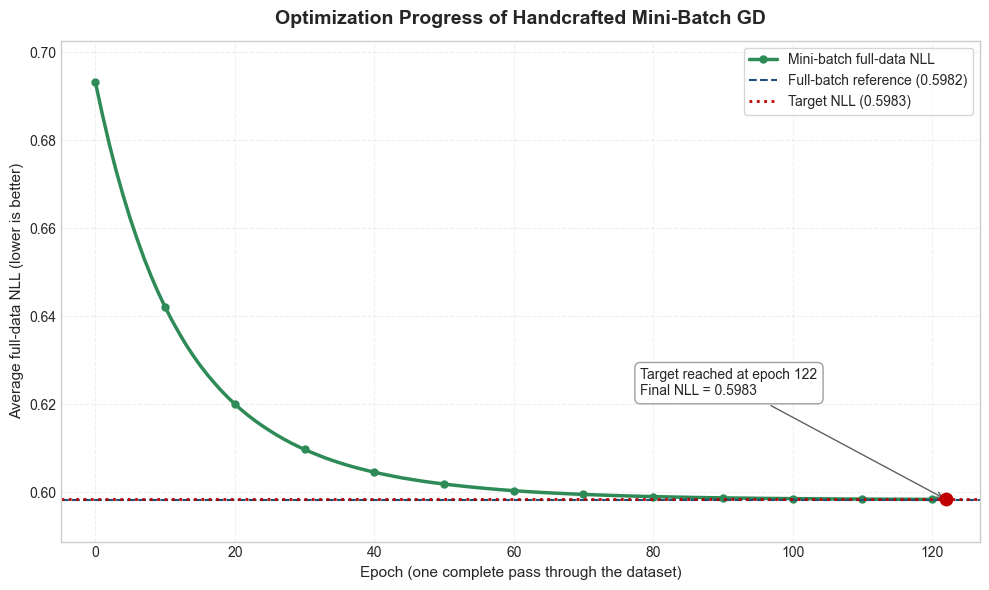

In [24]:
# Plot the full-data NLL during mini-batch optimization.

minibatch_nll_history = np.asarray(
    minibatch_result.nll_history,
    dtype=float,
)

minibatch_epochs = np.arange(
    len(minibatch_nll_history)
)

minibatch_final_epoch = (
    minibatch_result.epochs_completed
)

minibatch_final_nll = (
    minibatch_nll_history[-1]
)

marker_spacing = max(
    1,
    len(minibatch_epochs) // 12,
)

figure, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    minibatch_epochs,
    minibatch_nll_history,
    color="#2E8B57",
    linewidth=2.5,
    marker="o",
    markersize=5,
    markevery=marker_spacing,
    label="Mini-batch full-data NLL",
)

axis.axhline(
    y=reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.5,
    label=f"Full-batch reference ({reference_nll:.4f})",
)

axis.axhline(
    y=target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

axis.scatter(
    minibatch_final_epoch,
    minibatch_final_nll,
    color="#C00000",
    s=80,
    zorder=4,
)

axis.annotate(
    (
        f"Target reached at epoch "
        f"{minibatch_final_epoch:,}\n"
        f"Final NLL = {minibatch_final_nll:.4f}"
    ),
    xy=(
        minibatch_final_epoch,
        minibatch_final_nll,
    ),
    xytext=(-220, 75),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Average full-data NLL (lower is better)",
    fontsize=11,
)

axis.set_title(
    "Optimization Progress of Handcrafted Mini-Batch GD",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.04, y=0.1)

plt.tight_layout()
plt.show()

### Experiment 4: Handcrafted Momentum Gradient Descent


In [25]:
# Fit the model using convergence-driven momentum gradient descent.

momentum_learning_rate = minibatch_learning_rate
momentum_coefficient = 0.9

momentum_result = optimize_with_momentum_gradient_descent(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=momentum_learning_rate,
    batch_size=MINIBATCH_SIZE,
    momentum=momentum_coefficient,
    random_seed=SEED,
    target_nll=target_nll,
)

momentum_recovery_error = parameter_recovery_error(
    true_parameters,
    momentum_result.parameters,
)

momentum_final_nll = float(
    momentum_result.nll_history[-1]
)

momentum_target_reached = (
    momentum_final_nll <= target_nll
)

momentum_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Momentum coefficient",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{momentum_learning_rate:.4f}",
        f"{momentum_coefficient:.4f}",
        str(MINIBATCH_SIZE),
        str(batches_per_epoch),
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{momentum_result.nll_history[0]:.4f}",
        f"{momentum_final_nll:.4f}",
        f"{momentum_recovery_error:.4f}",
        f"{momentum_result.epochs_completed:,}",
        f"{int(momentum_result.update_count_history[-1]):,}",
        str(momentum_target_reached),
        momentum_result.stopping_reason,
        f"{momentum_result.runtime_seconds:.4f}",
        f"{momentum_result.parameters.sum():.4e}",
    ],
})

momentum_summary

,Quantity,Value
0,Learning rate,0.0100
1,Momentum coefficient,0.9000
2,Mini-batch size,128
3,Batches per epoch,79
4,Reference full-batch NLL,0.5982
5,Target NLL,0.5983
6,Initial NLL,0.6931
7,Final NLL,0.5983
8,Parameter-recovery RMSE,0.0463
9,Epochs completed,12


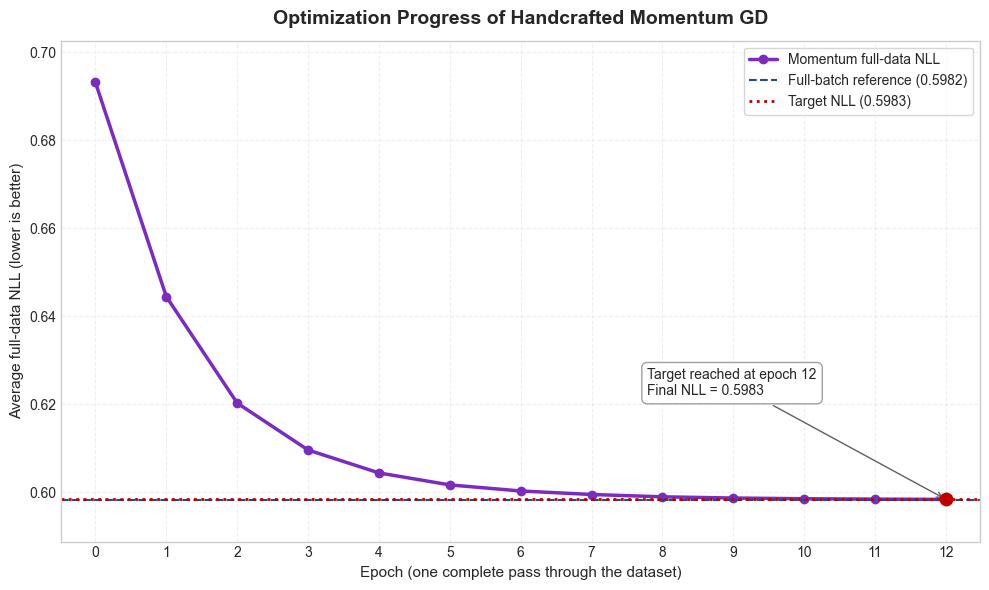

In [26]:
# Plot the full-data NLL during momentum optimization.

momentum_nll_history = np.asarray(
    momentum_result.nll_history,
    dtype=float,
)

momentum_epochs = np.arange(
    len(momentum_nll_history)
)

momentum_final_epoch = (
    momentum_result.epochs_completed
)

momentum_final_nll = (
    momentum_nll_history[-1]
)

figure, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    momentum_epochs,
    momentum_nll_history,
    color="#7B2CBF",
    linewidth=2.5,
    marker="o",
    markersize=6,
    label="Momentum full-data NLL",
)

axis.axhline(
    y=reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.5,
    label=f"Full-batch reference ({reference_nll:.4f})",
)

axis.axhline(
    y=target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

axis.scatter(
    momentum_final_epoch,
    momentum_final_nll,
    color="#C00000",
    s=80,
    zorder=4,
)

axis.annotate(
    (
        f"Target reached at epoch "
        f"{momentum_final_epoch:,}\n"
        f"Final NLL = {momentum_final_nll:.4f}"
    ),
    xy=(
        momentum_final_epoch,
        momentum_final_nll,
    ),
    xytext=(-215, 75),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Average full-data NLL (lower is better)",
    fontsize=11,
)

axis.set_title(
    "Optimization Progress of Handcrafted Momentum GD",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.set_xticks(momentum_epochs)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.04, y=0.1)

plt.tight_layout()
plt.show()

### Experiment 5: Handcrafted Adam


In [27]:
# Fit the model using convergence-driven handcrafted Adam.

adam_learning_rate = 0.01
adam_beta_1 = 0.9
adam_beta_2 = 0.999
adam_epsilon = 1e-8

adam_result = optimize_with_adam(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=adam_learning_rate,
    batch_size=MINIBATCH_SIZE,
    beta_1=adam_beta_1,
    beta_2=adam_beta_2,
    epsilon=adam_epsilon,
    random_seed=SEED,
    target_nll=target_nll,
)

adam_recovery_error = parameter_recovery_error(
    true_parameters,
    adam_result.parameters,
)

adam_final_nll = float(
    adam_result.nll_history[-1]
)

adam_target_reached = (
    adam_final_nll <= target_nll
)

adam_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Beta 1",
        "Beta 2",
        "Epsilon",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{adam_learning_rate:.4f}",
        f"{adam_beta_1:.4f}",
        f"{adam_beta_2:.4f}",
        f"{adam_epsilon:.4e}",
        str(MINIBATCH_SIZE),
        str(batches_per_epoch),
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{adam_result.nll_history[0]:.4f}",
        f"{adam_final_nll:.4f}",
        f"{adam_recovery_error:.4f}",
        f"{adam_result.epochs_completed:,}",
        f"{int(adam_result.update_count_history[-1]):,}",
        str(adam_target_reached),
        adam_result.stopping_reason,
        f"{adam_result.runtime_seconds:.4f}",
        f"{adam_result.parameters.sum():.4e}",
    ],
})

adam_summary

,Quantity,Value
0,Learning rate,0.0100
1,Beta 1,0.9000
2,Beta 2,0.9990
3,Epsilon,1.0000e-08
4,Mini-batch size,128
5,Batches per epoch,79
6,Reference full-batch NLL,0.5982
7,Target NLL,0.5983
8,Initial NLL,0.6931
9,Final NLL,0.5983


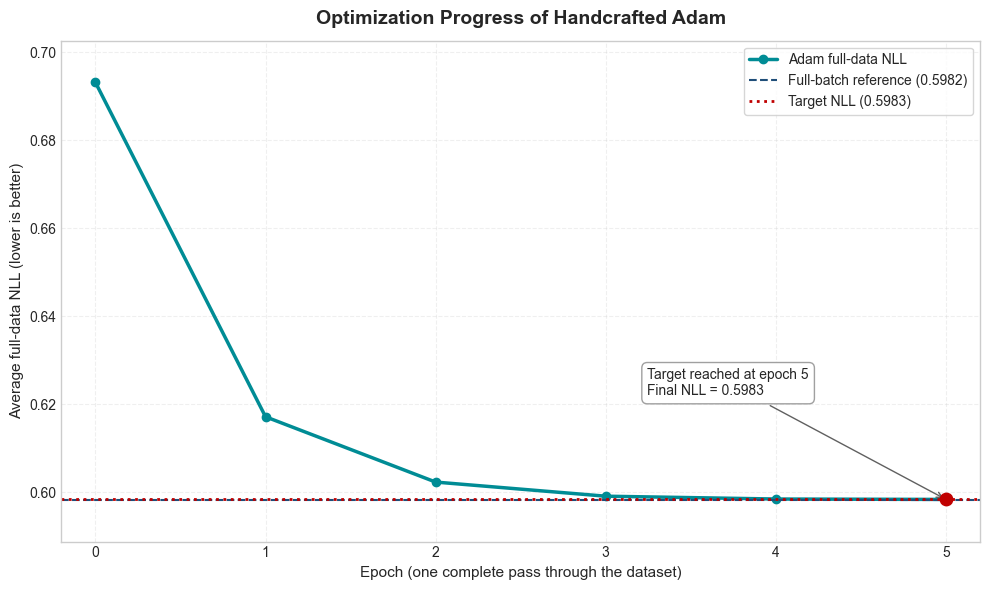

In [28]:
# Plot the full-data NLL during Adam optimization.

adam_nll_history = np.asarray(
    adam_result.nll_history,
    dtype=float,
)

adam_epochs = np.arange(
    len(adam_nll_history)
)

adam_final_epoch = adam_result.epochs_completed
adam_final_nll = adam_nll_history[-1]

marker_spacing = max(
    1,
    len(adam_epochs) // 12,
)

figure, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    adam_epochs,
    adam_nll_history,
    color="#008C95",
    linewidth=2.5,
    marker="o",
    markersize=6,
    markevery=marker_spacing,
    label="Adam full-data NLL",
)

axis.axhline(
    y=reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.5,
    label=f"Full-batch reference ({reference_nll:.4f})",
)

axis.axhline(
    y=target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

axis.scatter(
    adam_final_epoch,
    adam_final_nll,
    color="#C00000",
    s=80,
    zorder=4,
)

axis.annotate(
    (
        f"Target reached at epoch "
        f"{adam_final_epoch:,}\n"
        f"Final NLL = {adam_final_nll:.4f}"
    ),
    xy=(
        adam_final_epoch,
        adam_final_nll,
    ),
    xytext=(-215, 75),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Average full-data NLL (lower is better)",
    fontsize=11,
)

axis.set_title(
    "Optimization Progress of Handcrafted Adam",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.04, y=0.1)

plt.tight_layout()
plt.show()

### Comparison of Handcrafted Optimizers


In [29]:
# Run full-batch GD using the common target for a fair comparison.

full_batch_target_result = (
    optimize_with_full_batch_gradient_descent(
        number_of_items=NUMBER_OF_ITEMS,
        comparisons=comparisons,
        learning_rate=full_batch_learning_rate,
        target_nll=target_nll,
    )
)

handcrafted_result_details = [
    (
        "Full-batch GD",
        full_batch_target_result,
        NUMBER_OF_COMPARISONS,
    ),
    (
        "SGD",
        sgd_result,
        1,
    ),
    (
        "Mini-batch GD",
        minibatch_result,
        MINIBATCH_SIZE,
    ),
    (
        "Momentum GD",
        momentum_result,
        MINIBATCH_SIZE,
    ),
    (
        "Adam",
        adam_result,
        MINIBATCH_SIZE,
    ),
]

comparison_rows = []

for (
    optimizer_name,
    optimization_result,
    batch_size,
) in handcrafted_result_details:

    final_nll = float(
        optimization_result.nll_history[-1]
    )

    comparison_rows.append({
        "Optimizer": optimizer_name,
        "Batch size": batch_size,
        "Final NLL": final_nll,
        "Recovery RMSE": parameter_recovery_error(
            true_parameters,
            optimization_result.parameters,
        ),
        "Epochs": optimization_result.epochs_completed,
        "Parameter updates": int(
            optimization_result
            .update_count_history[-1]
        ),
        "Runtime (seconds)": (
            optimization_result.runtime_seconds
        ),
        "Target reached": final_nll <= target_nll,
        "Stopping reason": (
            optimization_result.stopping_reason
        ),
    })

handcrafted_comparison_table = pd.DataFrame(
    comparison_rows
)

display(
    handcrafted_comparison_table.style.format({
        "Batch size": "{:,}",
        "Final NLL": "{:.4f}",
        "Recovery RMSE": "{:.4f}",
        "Epochs": "{:,}",
        "Parameter updates": "{:,}",
        "Runtime (seconds)": "{:.4f}",
    })
)

,Optimizer,Batch size,Final NLL,Recovery RMSE,Epochs,Parameter updates,Runtime (seconds),Target reached,Stopping reason
0,Full-batch GD,"10,000",0.5983,0.0437,961,961,0.5937,True,target NLL reached
1,SGD,1,0.5983,0.0440,10,"100,000",3.0043,True,target NLL reached
2,Mini-batch GD,128,0.5983,0.0439,122,"9,638",0.6569,True,target NLL reached
3,Momentum GD,128,0.5983,0.0463,12,948,0.1248,True,target NLL reached
4,Adam,128,0.5983,0.0359,5,395,0.0295,True,target NLL reached


#### Computational Comparison

The optimizers are compared using three measures: Epochs, Parameter and runtime.


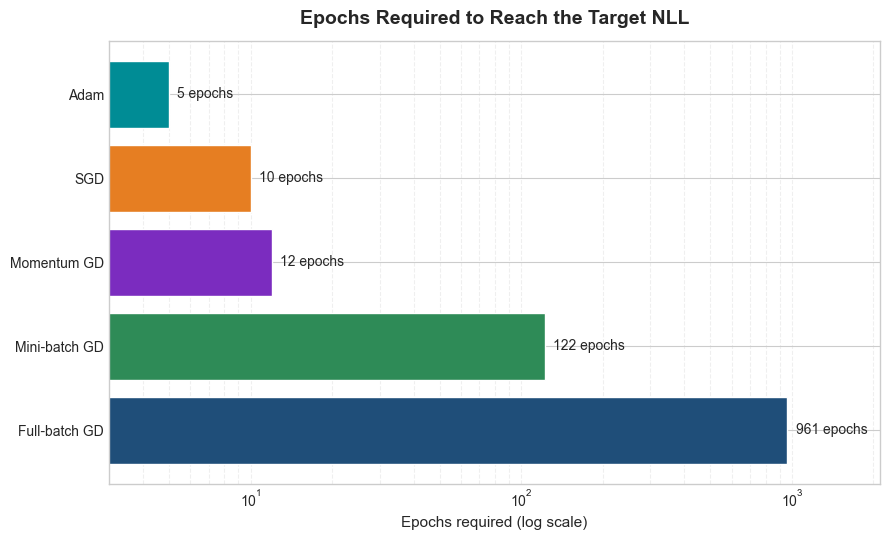

In [31]:
# Compare the epochs required to reach the target NLL.

optimizer_colors = {
    "Full-batch GD": "#1F4E79",
    "SGD": "#E67E22",
    "Mini-batch GD": "#2E8B57",
    "Momentum GD": "#7B2CBF",
    "Adam": "#008C95",
}

epoch_comparison = (
    handcrafted_comparison_table[
        [
            "Optimizer",
            "Epochs",
        ]
    ]
    .sort_values("Epochs")
    .reset_index(drop=True)
)

epoch_colors = [
    optimizer_colors[name]
    for name in epoch_comparison["Optimizer"]
]

figure, axis = plt.subplots(figsize=(9, 5.5))

bars = axis.barh(
    epoch_comparison["Optimizer"],
    epoch_comparison["Epochs"],
    color=epoch_colors,
    edgecolor="white",
)

axis.set_xscale("log")
axis.invert_yaxis()

axis.bar_label(
    bars,
    labels=[
        f"{int(value):,} epochs"
        for value in epoch_comparison["Epochs"]
    ],
    padding=6,
    fontsize=10,
)

axis.set_xlabel(
    "Epochs required (log scale)",
    fontsize=11,
)

axis.set_ylabel("")

axis.set_title(
    "Epochs Required to Reach the Target NLL",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.grid(
    True,
    axis="x",
    which="both",
    linestyle="--",
    alpha=0.3,
)

axis.set_axisbelow(True)

axis.set_xlim(
    epoch_comparison["Epochs"].min() * 0.6,
    epoch_comparison["Epochs"].max() * 2.2,
)

plt.tight_layout()
plt.show()

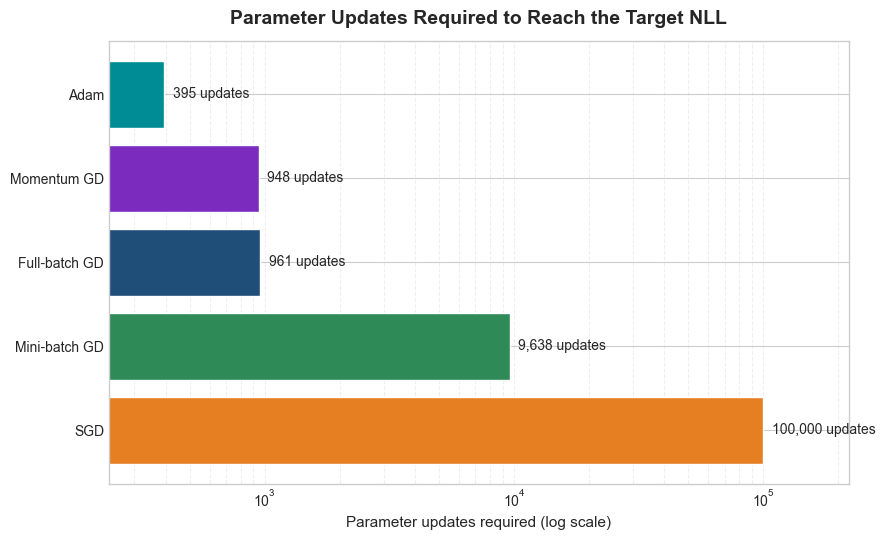

In [32]:
# Compare the parameter updates required to reach the target NLL.

update_comparison = (
    handcrafted_comparison_table[
        [
            "Optimizer",
            "Parameter updates",
        ]
    ]
    .sort_values("Parameter updates")
    .reset_index(drop=True)
)

update_colors = [
    optimizer_colors[name]
    for name in update_comparison["Optimizer"]
]

figure, axis = plt.subplots(figsize=(9, 5.5))

bars = axis.barh(
    update_comparison["Optimizer"],
    update_comparison["Parameter updates"],
    color=update_colors,
    edgecolor="white",
)

axis.set_xscale("log")
axis.invert_yaxis()

axis.bar_label(
    bars,
    labels=[
        f"{int(value):,} updates"
        for value in update_comparison[
            "Parameter updates"
        ]
    ],
    padding=6,
    fontsize=10,
)

axis.set_xlabel(
    "Parameter updates required (log scale)",
    fontsize=11,
)

axis.set_ylabel("")

axis.set_title(
    "Parameter Updates Required to Reach the Target NLL",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.grid(
    True,
    axis="x",
    which="both",
    linestyle="--",
    alpha=0.3,
)

axis.set_axisbelow(True)

axis.set_xlim(
    update_comparison[
        "Parameter updates"
    ].min() * 0.6,
    update_comparison[
        "Parameter updates"
    ].max() * 2.2,
)

plt.tight_layout()
plt.show()

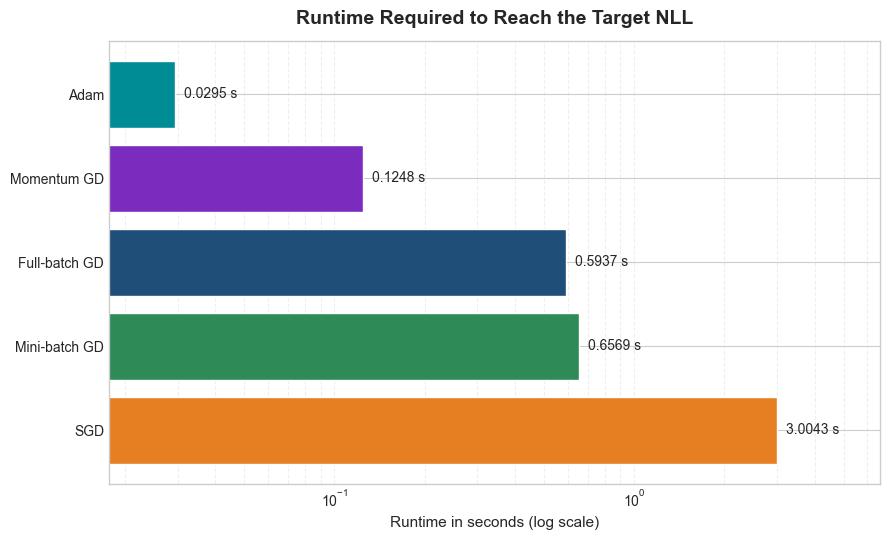

In [33]:
# Compare the measured runtime of each optimizer.

runtime_comparison = (
    handcrafted_comparison_table[
        [
            "Optimizer",
            "Runtime (seconds)",
        ]
    ]
    .sort_values("Runtime (seconds)")
    .reset_index(drop=True)
)

runtime_colors = [
    optimizer_colors[name]
    for name in runtime_comparison["Optimizer"]
]

figure, axis = plt.subplots(figsize=(9, 5.5))

bars = axis.barh(
    runtime_comparison["Optimizer"],
    runtime_comparison["Runtime (seconds)"],
    color=runtime_colors,
    edgecolor="white",
)

axis.set_xscale("log")
axis.invert_yaxis()

axis.bar_label(
    bars,
    labels=[
        f"{value:.4f} s"
        for value in runtime_comparison[
            "Runtime (seconds)"
        ]
    ],
    padding=6,
    fontsize=10,
)

axis.set_xlabel(
    "Runtime in seconds (log scale)",
    fontsize=11,
)

axis.set_ylabel("")

axis.set_title(
    "Runtime Required to Reach the Target NLL",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.grid(
    True,
    axis="x",
    which="both",
    linestyle="--",
    alpha=0.3,
)

axis.set_axisbelow(True)

axis.set_xlim(
    runtime_comparison[
        "Runtime (seconds)"
    ].min() * 0.6,
    runtime_comparison[
        "Runtime (seconds)"
    ].max() * 2.2,
)

plt.tight_layout()
plt.show()

## PyTorch Optimizers
The same optimization experiments are now repeated using PyTorch.

In [34]:
# Define the shared PyTorch experiment settings.

PYTORCH_DEVICE = torch.device("cpu")
PYTORCH_DTYPE = torch.float64

torch.manual_seed(SEED)

pytorch_settings = pd.DataFrame({
    "Setting": [
        "PyTorch version",
        "Device",
        "Data type",
        "Random seed",
        "Number of items",
        "Number of comparisons",
        "Mini-batch size",
        "Reference NLL",
        "Target NLL",
    ],
    "Value": [
        torch.__version__,
        str(PYTORCH_DEVICE),
        str(PYTORCH_DTYPE),
        str(SEED),
        str(NUMBER_OF_ITEMS),
        f"{NUMBER_OF_COMPARISONS:,}",
        str(MINIBATCH_SIZE),
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
    ],
})

pytorch_settings

,Setting,Value
0,PyTorch version,2.13.0
1,Device,cpu
2,Data type,torch.float64
3,Random seed,20260831
4,Number of items,10
5,Number of comparisons,"10,000"
6,Mini-batch size,128
7,Reference NLL,0.5982
8,Target NLL,0.5983


In [ ]:
# Temporary inspection of the reusable PyTorch functions written in /src folder.

import inspect
import bradley_terry.pytorch_optimization as bt_torch

pytorch_functions = pd.DataFrame(
    [
        {
            "Function": name,
            "Signature": str(inspect.signature(function)),
        }
        for name, function in vars(bt_torch).items()
        if callable(function)
        and function.__module__ == bt_torch.__name__
        and not name.startswith("_")
    ]
).sort_values("Function", ignore_index=True)

pytorch_functions

# print(
#     inspect.signature(
#         bt_torch.optimize_with_pytorch_full_batch_gradient_descent
#     )
# )

(number_of_items: int, comparisons: collections.abc.Sequence[tuple[int, int]], *, learning_rate: float = 0.1, gradient_tolerance: float = 1e-06, target_nll: float | None = None, initial_parameters: numpy.ndarray | None = None, emergency_maximum_epochs: int = 100000) -> bradley_terry.optimization.OptimizationResult


### Experiment 6: PyTorch Full-Batch Gradient Descent

In [37]:
# Run PyTorch full-batch gradient descent until it reaches the common NLL target.

PYTORCH_FULL_BATCH_LEARNING_RATE = 0.1

pytorch_full_batch_result = (
    bt_torch.optimize_with_pytorch_full_batch_gradient_descent(
        number_of_items=NUMBER_OF_ITEMS,
        comparisons=comparisons,
        learning_rate=PYTORCH_FULL_BATCH_LEARNING_RATE,
        gradient_tolerance=GRADIENT_TOLERANCE,
        target_nll=target_nll,
        initial_parameters=np.zeros(NUMBER_OF_ITEMS),
    )
)

pytorch_full_batch_recovery_error = parameter_recovery_error(
    true_parameters,
    pytorch_full_batch_result.parameters,
)

pytorch_full_batch_target_reached = (
    pytorch_full_batch_result.nll_history[-1] <= target_nll
)

pytorch_full_batch_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{PYTORCH_FULL_BATCH_LEARNING_RATE:.4f}",
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{pytorch_full_batch_result.nll_history[0]:.4f}",
        f"{pytorch_full_batch_result.nll_history[-1]:.4f}",
        f"{pytorch_full_batch_recovery_error:.4f}",
        f"{pytorch_full_batch_result.epochs_completed:,}",
        f"{int(pytorch_full_batch_result.update_count_history[-1]):,}",
        str(pytorch_full_batch_target_reached),
        pytorch_full_batch_result.stopping_reason,
        f"{pytorch_full_batch_result.runtime_seconds:.4f}",
        f"{pytorch_full_batch_result.parameters.sum():.4e}",
    ],
})

pytorch_full_batch_summary

,Quantity,Value
0,Learning rate,0.1000
1,Reference full-batch NLL,0.5982
2,Target NLL,0.5983
3,Initial NLL,0.6931
4,Final NLL,0.5983
5,Parameter-recovery RMSE,0.0437
6,Epochs completed,961
7,Parameter updates,961
8,Target reached,True
9,Stopping reason,target NLL reached


Here, we can see that the difference between the result of using handcraft technique and pytorch has just one: the runtime, as runtime Handcrafted is 0.59 but pytorch is 0.75
The reason of the same is the autograd overhead for a small BTL model problems makes it slightly slower as the parameter count taken till now was also 10 parameters, and maybe for all the next experiments having just '10 params', the runtime might be greater.

### Experiment 7: PyTorch Stochastic Gradient Descent


In [39]:
# Run PyTorch SGD until it reaches the common NLL target.

PYTORCH_SGD_LEARNING_RATE = 0.001

pytorch_sgd_result = (
    bt_torch.optimize_with_pytorch_stochastic_gradient_descent(
        number_of_items=NUMBER_OF_ITEMS,
        comparisons=comparisons,
        learning_rate=PYTORCH_SGD_LEARNING_RATE,
        random_seed=SEED,
        gradient_tolerance=GRADIENT_TOLERANCE,
        target_nll=target_nll,
        initial_parameters=np.zeros(NUMBER_OF_ITEMS),
    )
)

pytorch_sgd_recovery_error = parameter_recovery_error(
    true_parameters,
    pytorch_sgd_result.parameters,
)

pytorch_sgd_target_reached = (
    pytorch_sgd_result.nll_history[-1] <= target_nll
)

pytorch_sgd_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Reference full-batch NLL",
        "Allowed NLL margin",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{PYTORCH_SGD_LEARNING_RATE:.4f}",
        f"{reference_nll:.4f}",
        f"{NLL_TARGET_MARGIN:.4e}",
        f"{target_nll:.4f}",
        f"{pytorch_sgd_result.nll_history[0]:.4f}",
        f"{pytorch_sgd_result.nll_history[-1]:.4f}",
        f"{pytorch_sgd_recovery_error:.4f}",
        f"{pytorch_sgd_result.epochs_completed:,}",
        f"{int(pytorch_sgd_result.update_count_history[-1]):,}",
        str(pytorch_sgd_target_reached),
        pytorch_sgd_result.stopping_reason,
        f"{pytorch_sgd_result.runtime_seconds:.4f}",
        f"{pytorch_sgd_result.parameters.sum():.4e}",
    ],
})

pytorch_sgd_summary

,Quantity,Value
0,Learning rate,0.0010
1,Reference full-batch NLL,0.5982
2,Allowed NLL margin,1.0000e-04
3,Target NLL,0.5983
4,Initial NLL,0.6931
5,Final NLL,0.5983
6,Parameter-recovery RMSE,0.0411
7,Epochs completed,10
8,Parameter updates,"100,000"
9,Target reached,True


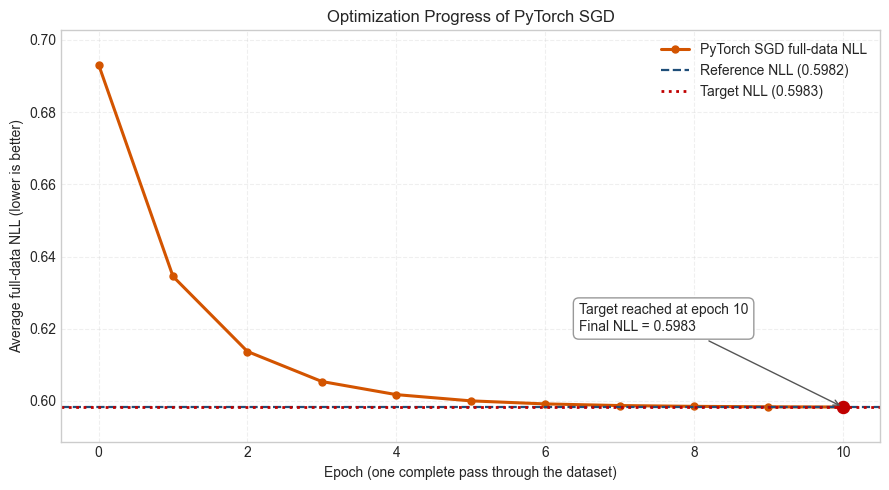

In [40]:
# Plot the full-data NLL measured after each PyTorch SGD epoch.

pytorch_sgd_epochs = np.arange(
    len(pytorch_sgd_result.nll_history)
)

figure, axis = plt.subplots(figsize=(9, 5))

axis.plot(
    pytorch_sgd_epochs,
    pytorch_sgd_result.nll_history,
    color="#D35400",
    marker="o",
    markersize=5,
    linewidth=2.2,
    label="PyTorch SGD full-data NLL",
)

axis.axhline(
    reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.6,
    label=f"Reference NLL ({reference_nll:.4f})",
)

axis.axhline(
    target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

final_epoch = pytorch_sgd_epochs[-1]
final_nll = pytorch_sgd_result.nll_history[-1]

axis.scatter(
    final_epoch,
    final_nll,
    color="#C00000",
    s=75,
    zorder=3,
)

axis.annotate(
    f"Target reached at epoch {final_epoch:,}\n"
    f"Final NLL = {final_nll:.4f}",
    xy=(final_epoch, final_nll),
    xytext=(-190, 55),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#555555"},
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#999999",
    },
)

axis.set_xlabel("Epoch (one complete pass through the dataset)")
axis.set_ylabel("Average full-data NLL (lower is better)")
axis.set_title("Optimization Progress of PyTorch SGD")
axis.legend(loc="upper right")
axis.grid(True, linestyle="--", alpha=0.3)
axis.margins(x=0.05, y=0.1)

plt.tight_layout()
plt.show()

### Experiment 8: PyTorch Mini-Batch Gradient Descent


In [42]:
# Run PyTorch mini-batch GD until it reaches the common NLL target.

PYTORCH_MINIBATCH_LEARNING_RATE = 0.05

pytorch_minibatch_result = (
    bt_torch.optimize_with_pytorch_minibatch_gradient_descent(
        number_of_items=NUMBER_OF_ITEMS,
        comparisons=comparisons,
        learning_rate=PYTORCH_MINIBATCH_LEARNING_RATE,
        batch_size=MINIBATCH_SIZE,
        random_seed=SEED,
        gradient_tolerance=GRADIENT_TOLERANCE,
        target_nll=target_nll,
        initial_parameters=np.zeros(NUMBER_OF_ITEMS),
    )
)

pytorch_minibatch_recovery_error = parameter_recovery_error(
    true_parameters,
    pytorch_minibatch_result.parameters,
)

pytorch_minibatch_target_reached = (
    pytorch_minibatch_result.nll_history[-1] <= target_nll
)

pytorch_minibatch_batches_per_epoch = int(
    np.ceil(NUMBER_OF_COMPARISONS / MINIBATCH_SIZE)
)

pytorch_minibatch_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{PYTORCH_MINIBATCH_LEARNING_RATE:.4f}",
        f"{MINIBATCH_SIZE:,}",
        f"{pytorch_minibatch_batches_per_epoch:,}",
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{pytorch_minibatch_result.nll_history[0]:.4f}",
        f"{pytorch_minibatch_result.nll_history[-1]:.4f}",
        f"{pytorch_minibatch_recovery_error:.4f}",
        f"{pytorch_minibatch_result.epochs_completed:,}",
        f"{int(pytorch_minibatch_result.update_count_history[-1]):,}",
        str(pytorch_minibatch_target_reached),
        pytorch_minibatch_result.stopping_reason,
        f"{pytorch_minibatch_result.runtime_seconds:.4f}",
        f"{pytorch_minibatch_result.parameters.sum():.4e}",
    ],
})

pytorch_minibatch_summary

,Quantity,Value
0,Learning rate,0.0500
1,Mini-batch size,128
2,Batches per epoch,79
3,Reference full-batch NLL,0.5982
4,Target NLL,0.5983
5,Initial NLL,0.6931
6,Final NLL,0.5983
7,Parameter-recovery RMSE,0.0422
8,Epochs completed,24
9,Parameter updates,"1,896"


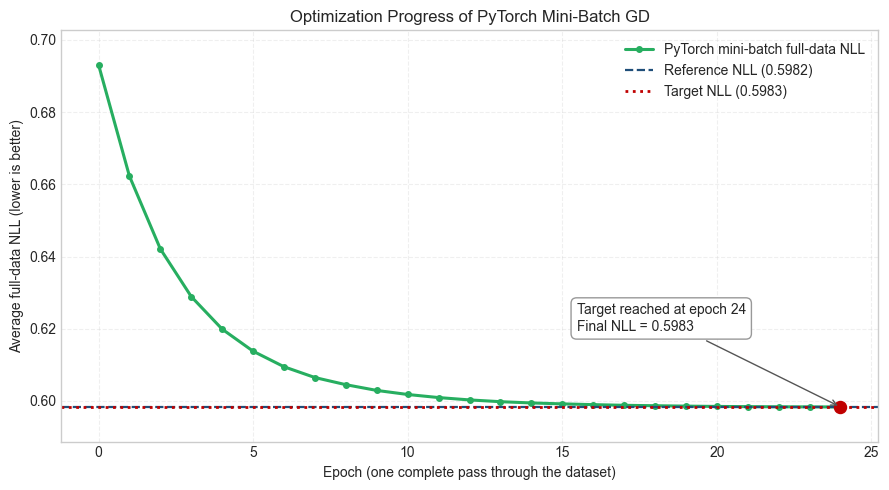

In [43]:
# Plot the full-data NLL measured after each PyTorch mini-batch epoch.

pytorch_minibatch_epochs = np.arange(
    len(pytorch_minibatch_result.nll_history)
)

figure, axis = plt.subplots(figsize=(9, 5))

axis.plot(
    pytorch_minibatch_epochs,
    pytorch_minibatch_result.nll_history,
    color="#27AE60",
    marker="o",
    markersize=4,
    linewidth=2.2,
    label="PyTorch mini-batch full-data NLL",
)

axis.axhline(
    reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.6,
    label=f"Reference NLL ({reference_nll:.4f})",
)

axis.axhline(
    target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

final_epoch = pytorch_minibatch_epochs[-1]
final_nll = pytorch_minibatch_result.nll_history[-1]

axis.scatter(
    final_epoch,
    final_nll,
    color="#C00000",
    s=75,
    zorder=3,
)

axis.annotate(
    f"Target reached at epoch {final_epoch:,}\n"
    f"Final NLL = {final_nll:.4f}",
    xy=(final_epoch, final_nll),
    xytext=(-190, 55),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#555555"},
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#999999",
    },
)

axis.set_xlabel("Epoch (one complete pass through the dataset)")
axis.set_ylabel("Average full-data NLL (lower is better)")
axis.set_title("Optimization Progress of PyTorch Mini-Batch GD")
axis.legend(loc="upper right")
axis.grid(True, linestyle="--", alpha=0.3)
axis.margins(x=0.05, y=0.1)

plt.tight_layout()
plt.show()

### Experiment 9: PyTorch Momentum Gradient Descent


In [44]:
# Run PyTorch momentum GD until it reaches the common NLL target.

PYTORCH_MOMENTUM_LEARNING_RATE = 0.01
PYTORCH_MOMENTUM_COEFFICIENT = 0.9

pytorch_momentum_result = (
    bt_torch.optimize_with_pytorch_momentum_gradient_descent(
        number_of_items=NUMBER_OF_ITEMS,
        comparisons=comparisons,
        learning_rate=PYTORCH_MOMENTUM_LEARNING_RATE,
        batch_size=MINIBATCH_SIZE,
        momentum=PYTORCH_MOMENTUM_COEFFICIENT,
        random_seed=SEED,
        gradient_tolerance=GRADIENT_TOLERANCE,
        target_nll=target_nll,
        initial_parameters=np.zeros(NUMBER_OF_ITEMS),
    )
)

pytorch_momentum_recovery_error = parameter_recovery_error(
    true_parameters,
    pytorch_momentum_result.parameters,
)

pytorch_momentum_target_reached = (
    pytorch_momentum_result.nll_history[-1] <= target_nll
)

pytorch_momentum_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Momentum coefficient",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{PYTORCH_MOMENTUM_LEARNING_RATE:.4f}",
        f"{PYTORCH_MOMENTUM_COEFFICIENT:.4f}",
        f"{MINIBATCH_SIZE:,}",
        f"{pytorch_minibatch_batches_per_epoch:,}",
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{pytorch_momentum_result.nll_history[0]:.4f}",
        f"{pytorch_momentum_result.nll_history[-1]:.4f}",
        f"{pytorch_momentum_recovery_error:.4f}",
        f"{pytorch_momentum_result.epochs_completed:,}",
        f"{int(pytorch_momentum_result.update_count_history[-1]):,}",
        str(pytorch_momentum_target_reached),
        pytorch_momentum_result.stopping_reason,
        f"{pytorch_momentum_result.runtime_seconds:.4f}",
        f"{pytorch_momentum_result.parameters.sum():.4e}",
    ],
})

pytorch_momentum_summary

,Quantity,Value
0,Learning rate,0.0100
1,Momentum coefficient,0.9000
2,Mini-batch size,128
3,Batches per epoch,79
4,Reference full-batch NLL,0.5982
5,Target NLL,0.5983
6,Initial NLL,0.6931
7,Final NLL,0.5983
8,Parameter-recovery RMSE,0.0432
9,Epochs completed,12


Here, learning rate 0.01, momentum 0.9, and batch size 128, was deliberstely used to match the handcrafted momentum experiment for a fair comparison.

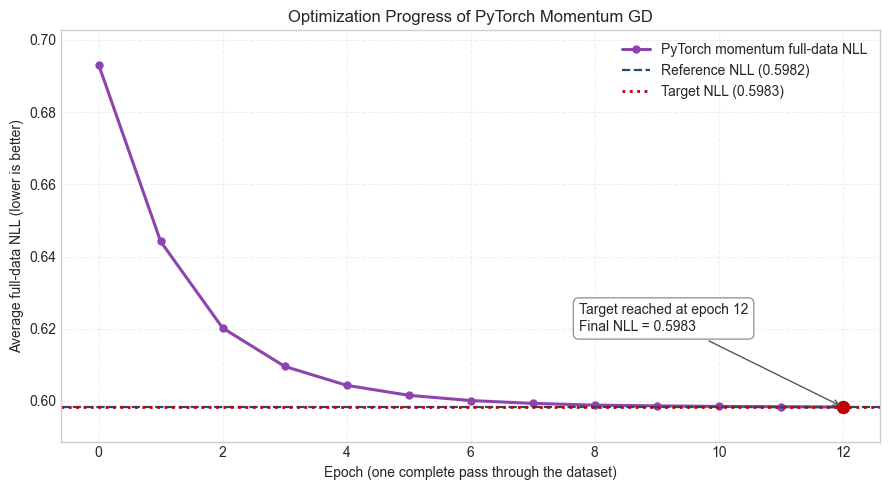

In [45]:
# Plot the full-data NLL measured after each PyTorch momentum epoch.

pytorch_momentum_epochs = np.arange(
    len(pytorch_momentum_result.nll_history)
)

figure, axis = plt.subplots(figsize=(9, 5))

axis.plot(
    pytorch_momentum_epochs,
    pytorch_momentum_result.nll_history,
    color="#8E44AD",
    marker="o",
    markersize=5,
    linewidth=2.2,
    label="PyTorch momentum full-data NLL",
)

axis.axhline(
    reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.6,
    label=f"Reference NLL ({reference_nll:.4f})",
)

axis.axhline(
    target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

final_epoch = pytorch_momentum_epochs[-1]
final_nll = pytorch_momentum_result.nll_history[-1]

axis.scatter(
    final_epoch,
    final_nll,
    color="#C00000",
    s=75,
    zorder=3,
)

axis.annotate(
    f"Target reached at epoch {final_epoch:,}\n"
    f"Final NLL = {final_nll:.4f}",
    xy=(final_epoch, final_nll),
    xytext=(-190, 55),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#555555"},
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#999999",
    },
)

axis.set_xlabel("Epoch (one complete pass through the dataset)")
axis.set_ylabel("Average full-data NLL (lower is better)")
axis.set_title("Optimization Progress of PyTorch Momentum GD")
axis.legend(loc="upper right")
axis.grid(True, linestyle="--", alpha=0.3)
axis.margins(x=0.05, y=0.1)

plt.tight_layout()
plt.show()

### Experiment 10: PyTorch Adam


In [46]:
# Run PyTorch Adam until it reaches the common NLL target.

PYTORCH_ADAM_LEARNING_RATE = 0.01
PYTORCH_ADAM_BETA_1 = 0.9
PYTORCH_ADAM_BETA_2 = 0.999
PYTORCH_ADAM_EPSILON = 1e-8

pytorch_adam_result = bt_torch.optimize_with_pytorch_adam(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=PYTORCH_ADAM_LEARNING_RATE,
    batch_size=MINIBATCH_SIZE,
    beta_1=PYTORCH_ADAM_BETA_1,
    beta_2=PYTORCH_ADAM_BETA_2,
    epsilon=PYTORCH_ADAM_EPSILON,
    random_seed=SEED,
    gradient_tolerance=GRADIENT_TOLERANCE,
    target_nll=target_nll,
    initial_parameters=np.zeros(NUMBER_OF_ITEMS),
)

pytorch_adam_recovery_error = parameter_recovery_error(
    true_parameters,
    pytorch_adam_result.parameters,
)

pytorch_adam_target_reached = (
    pytorch_adam_result.nll_history[-1] <= target_nll
)

pytorch_adam_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Beta 1",
        "Beta 2",
        "Epsilon",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{PYTORCH_ADAM_LEARNING_RATE:.4f}",
        f"{PYTORCH_ADAM_BETA_1:.4f}",
        f"{PYTORCH_ADAM_BETA_2:.4f}",
        f"{PYTORCH_ADAM_EPSILON:.1e}",
        f"{MINIBATCH_SIZE:,}",
        f"{pytorch_minibatch_batches_per_epoch:,}",
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{pytorch_adam_result.nll_history[0]:.4f}",
        f"{pytorch_adam_result.nll_history[-1]:.4f}",
        f"{pytorch_adam_recovery_error:.4f}",
        f"{pytorch_adam_result.epochs_completed:,}",
        f"{int(pytorch_adam_result.update_count_history[-1]):,}",
        str(pytorch_adam_target_reached),
        pytorch_adam_result.stopping_reason,
        f"{pytorch_adam_result.runtime_seconds:.4f}",
        f"{pytorch_adam_result.parameters.sum():.4e}",
    ],
})

pytorch_adam_summary

,Quantity,Value
0,Learning rate,0.0100
1,Beta 1,0.9000
2,Beta 2,0.9990
3,Epsilon,1.0e-08
4,Mini-batch size,128
5,Batches per epoch,79
6,Reference full-batch NLL,0.5982
7,Target NLL,0.5983
8,Initial NLL,0.6931
9,Final NLL,0.5983


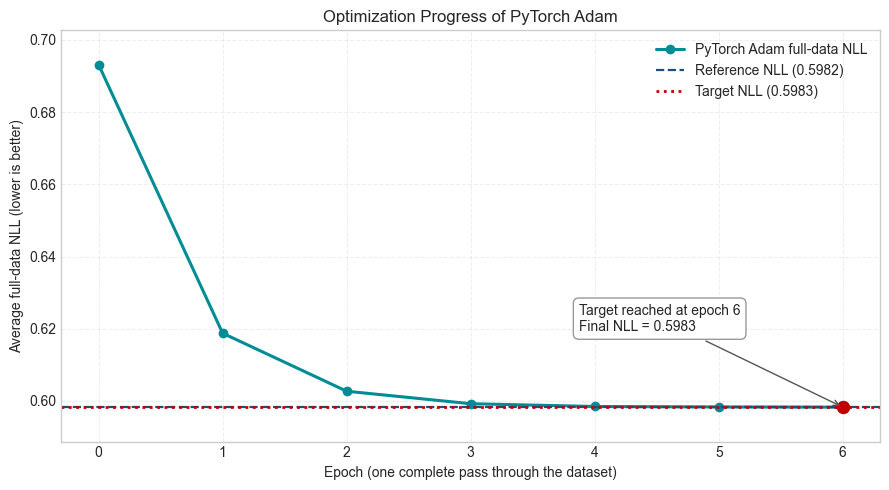

In [47]:
# Plot the full-data NLL measured after each PyTorch Adam epoch.

pytorch_adam_epochs = np.arange(
    len(pytorch_adam_result.nll_history)
)

figure, axis = plt.subplots(figsize=(9, 5))

axis.plot(
    pytorch_adam_epochs,
    pytorch_adam_result.nll_history,
    color="#008C95",
    marker="o",
    markersize=6,
    linewidth=2.2,
    label="PyTorch Adam full-data NLL",
)

axis.axhline(
    reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.6,
    label=f"Reference NLL ({reference_nll:.4f})",
)

axis.axhline(
    target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

final_epoch = pytorch_adam_epochs[-1]
final_nll = pytorch_adam_result.nll_history[-1]

axis.scatter(
    final_epoch,
    final_nll,
    color="#C00000",
    s=75,
    zorder=3,
)

axis.annotate(
    f"Target reached at epoch {final_epoch:,}\n"
    f"Final NLL = {final_nll:.4f}",
    xy=(final_epoch, final_nll),
    xytext=(-190, 55),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#555555"},
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#999999",
    },
)

axis.set_xlabel("Epoch (one complete pass through the dataset)")
axis.set_ylabel("Average full-data NLL (lower is better)")
axis.set_title("Optimization Progress of PyTorch Adam")
axis.legend(loc="upper right")
axis.grid(True, linestyle="--", alpha=0.3)
axis.margins(x=0.05, y=0.1)

plt.tight_layout()
plt.show()

## Comparison of Handcrafted and PyTorch Optimizers


In [48]:
# Collect all handcrafted and PyTorch results in one comparison table.

optimizer_results = [
    (
        "Handcrafted",
        "Full-batch GD",
        NUMBER_OF_COMPARISONS,
        full_batch_target_result,
    ),
    (
        "PyTorch",
        "Full-batch GD",
        NUMBER_OF_COMPARISONS,
        pytorch_full_batch_result,
    ),
    (
        "Handcrafted",
        "SGD",
        1,
        sgd_result,
    ),
    (
        "PyTorch",
        "SGD",
        1,
        pytorch_sgd_result,
    ),
    (
        "Handcrafted",
        "Mini-batch GD",
        MINIBATCH_SIZE,
        minibatch_result,
    ),
    (
        "PyTorch",
        "Mini-batch GD",
        MINIBATCH_SIZE,
        pytorch_minibatch_result,
    ),
    (
        "Handcrafted",
        "Momentum GD",
        MINIBATCH_SIZE,
        momentum_result,
    ),
    (
        "PyTorch",
        "Momentum GD",
        MINIBATCH_SIZE,
        pytorch_momentum_result,
    ),
    (
        "Handcrafted",
        "Adam",
        MINIBATCH_SIZE,
        adam_result,
    ),
    (
        "PyTorch",
        "Adam",
        MINIBATCH_SIZE,
        pytorch_adam_result,
    ),
]

comparison_rows = []

for implementation, optimizer, batch_size, result in optimizer_results:
    comparison_rows.append({
        "Implementation": implementation,
        "Optimizer": optimizer,
        "Batch size": batch_size,
        "Final NLL": result.nll_history[-1],
        "Recovery RMSE": parameter_recovery_error(
            true_parameters,
            result.parameters,
        ),
        "Epochs": result.epochs_completed,
        "Parameter updates": int(result.update_count_history[-1]),
        "Runtime (seconds)": result.runtime_seconds,
        "Target reached": result.nll_history[-1] <= target_nll,
    })

combined_comparison_table = pd.DataFrame(comparison_rows)

combined_comparison_table.style.format({
    "Batch size": "{:,}",
    "Final NLL": "{:.4f}",
    "Recovery RMSE": "{:.4f}",
    "Epochs": "{:,}",
    "Parameter updates": "{:,}",
    "Runtime (seconds)": "{:.4f}",
})

,Implementation,Optimizer,Batch size,Final NLL,Recovery RMSE,Epochs,Parameter updates,Runtime (seconds),Target reached
0,Handcrafted,Full-batch GD,"10,000",0.5983,0.0437,961,961,0.5937,True
1,PyTorch,Full-batch GD,"10,000",0.5983,0.0437,961,961,0.7495,True
2,Handcrafted,SGD,1,0.5983,0.0440,10,"100,000",3.0043,True
3,PyTorch,SGD,1,0.5983,0.0411,10,"100,000",7.5862,True
4,Handcrafted,Mini-batch GD,128,0.5983,0.0439,122,"9,638",0.6569,True
5,PyTorch,Mini-batch GD,128,0.5983,0.0422,24,"1,896",0.1830,True
6,Handcrafted,Momentum GD,128,0.5983,0.0463,12,948,0.1248,True
7,PyTorch,Momentum GD,128,0.5983,0.0432,12,948,0.2796,True
8,Handcrafted,Adam,128,0.5983,0.0359,5,395,0.0295,True
9,PyTorch,Adam,128,0.5983,0.0397,6,474,0.1216,True


### Epoch Comparison


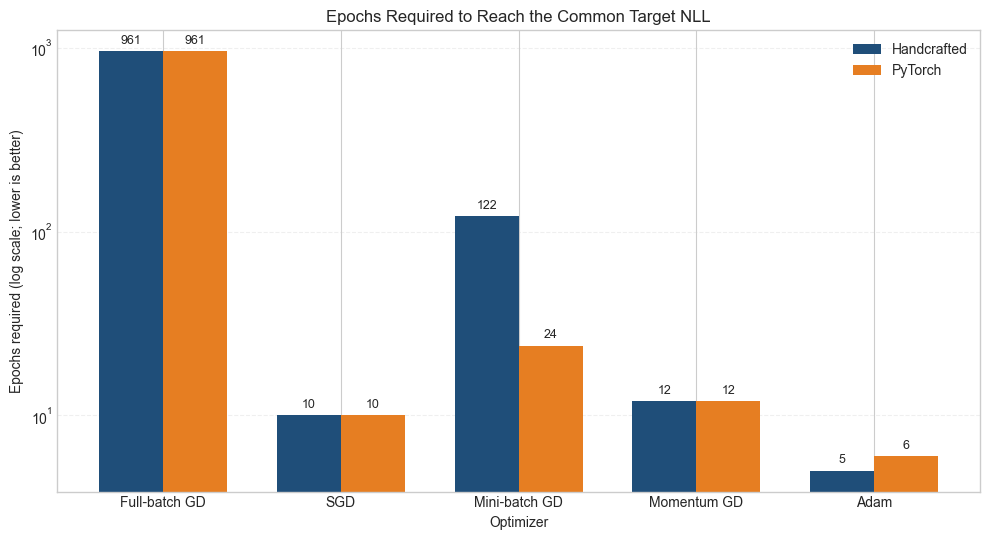

In [49]:
# Compare the epochs required by handcrafted and PyTorch optimizers.

optimizer_order = [
    "Full-batch GD",
    "SGD",
    "Mini-batch GD",
    "Momentum GD",
    "Adam",
]

epoch_plot_data = (
    combined_comparison_table
    .pivot(
        index="Optimizer",
        columns="Implementation",
        values="Epochs",
    )
    .reindex(optimizer_order)
)

x_positions = np.arange(len(optimizer_order))
bar_width = 0.36

figure, axis = plt.subplots(figsize=(10, 5.5))

handcrafted_bars = axis.bar(
    x_positions - bar_width / 2,
    epoch_plot_data["Handcrafted"],
    width=bar_width,
    color="#1F4E79",
    label="Handcrafted",
)

pytorch_bars = axis.bar(
    x_positions + bar_width / 2,
    epoch_plot_data["PyTorch"],
    width=bar_width,
    color="#E67E22",
    label="PyTorch",
)

axis.bar_label(
    handcrafted_bars,
    labels=[
        f"{int(value):,}"
        for value in epoch_plot_data["Handcrafted"]
    ],
    padding=3,
    fontsize=9,
)

axis.bar_label(
    pytorch_bars,
    labels=[
        f"{int(value):,}"
        for value in epoch_plot_data["PyTorch"]
    ],
    padding=3,
    fontsize=9,
)

axis.set_yscale("log")
axis.set_xticks(x_positions)
axis.set_xticklabels(optimizer_order)
axis.set_xlabel("Optimizer")
axis.set_ylabel("Epochs required (log scale; lower is better)")
axis.set_title("Epochs Required to Reach the Common Target NLL")
axis.legend()
axis.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Parameter-Update Comparison


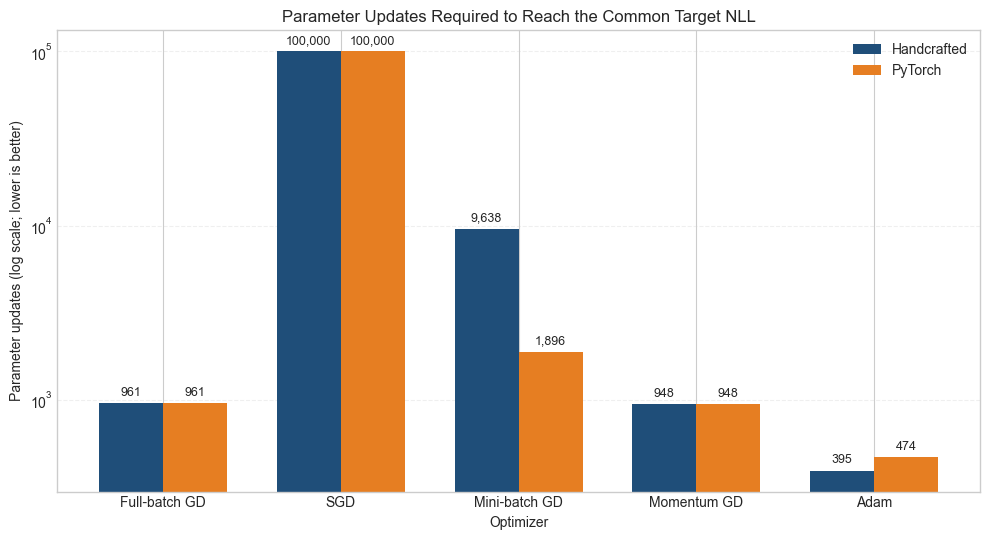

In [50]:
# Compare the number of parameter updates required to reach the target.

update_plot_data = (
    combined_comparison_table
    .pivot(
        index="Optimizer",
        columns="Implementation",
        values="Parameter updates",
    )
    .reindex(optimizer_order)
)

x_positions = np.arange(len(optimizer_order))
bar_width = 0.36

figure, axis = plt.subplots(figsize=(10, 5.5))

handcrafted_bars = axis.bar(
    x_positions - bar_width / 2,
    update_plot_data["Handcrafted"],
    width=bar_width,
    color="#1F4E79",
    label="Handcrafted",
)

pytorch_bars = axis.bar(
    x_positions + bar_width / 2,
    update_plot_data["PyTorch"],
    width=bar_width,
    color="#E67E22",
    label="PyTorch",
)

axis.bar_label(
    handcrafted_bars,
    labels=[
        f"{int(value):,}"
        for value in update_plot_data["Handcrafted"]
    ],
    padding=3,
    fontsize=9,
)

axis.bar_label(
    pytorch_bars,
    labels=[
        f"{int(value):,}"
        for value in update_plot_data["PyTorch"]
    ],
    padding=3,
    fontsize=9,
)

axis.set_yscale("log")
axis.set_xticks(x_positions)
axis.set_xticklabels(optimizer_order)
axis.set_xlabel("Optimizer")
axis.set_ylabel("Parameter updates (log scale; lower is better)")
axis.set_title("Parameter Updates Required to Reach the Common Target NLL")
axis.legend()
axis.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Runtime Comparison


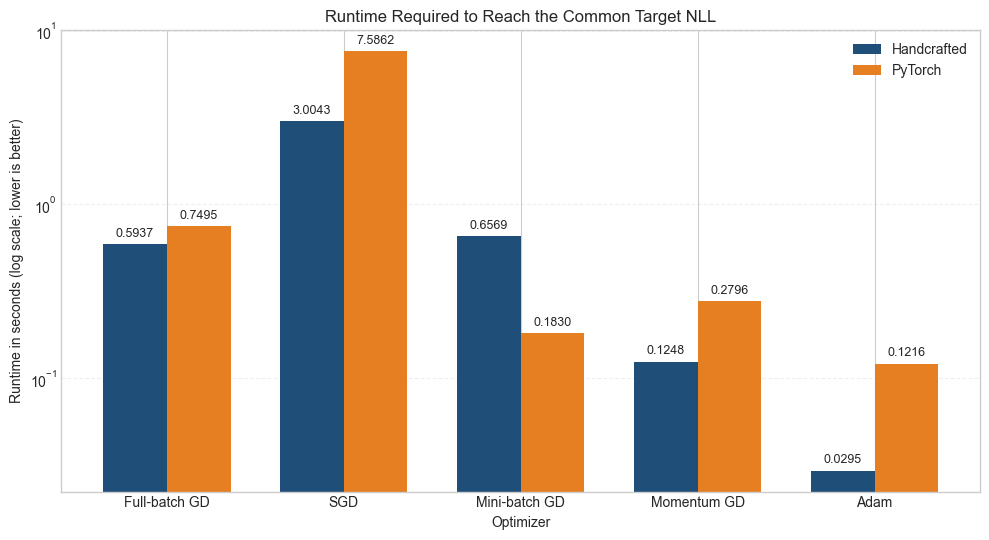

In [52]:

# Compare the measured runtime of handcrafted and PyTorch optimizers.

runtime_plot_data = (
    combined_comparison_table
    .pivot(
        index="Optimizer",
        columns="Implementation",
        values="Runtime (seconds)",
    )
    .reindex(optimizer_order)
)

x_positions = np.arange(len(optimizer_order))
bar_width = 0.36

figure, axis = plt.subplots(figsize=(10, 5.5))

handcrafted_bars = axis.bar(
    x_positions - bar_width / 2,
    runtime_plot_data["Handcrafted"],
    width=bar_width,
    color="#1F4E79",
    label="Handcrafted",
)

pytorch_bars = axis.bar(
    x_positions + bar_width / 2,
    runtime_plot_data["PyTorch"],
    width=bar_width,
    color="#E67E22",
    label="PyTorch",
)

axis.bar_label(
    handcrafted_bars,
    labels=[
        f"{value:.4f}"
        for value in runtime_plot_data["Handcrafted"]
    ],
    padding=3,
    fontsize=9,
)

axis.bar_label(
    pytorch_bars,
    labels=[
        f"{value:.4f}"
        for value in runtime_plot_data["PyTorch"]
    ],
    padding=3,
    fontsize=9,
)

axis.set_yscale("log")
axis.set_xticks(x_positions)
axis.set_xticklabels(optimizer_order)
axis.set_xlabel("Optimizer")
axis.set_ylabel("Runtime in seconds (log scale; lower is better)")
axis.set_title("Runtime Required to Reach the Common Target NLL")
axis.legend()
axis.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Parameter-Recovery Comparison


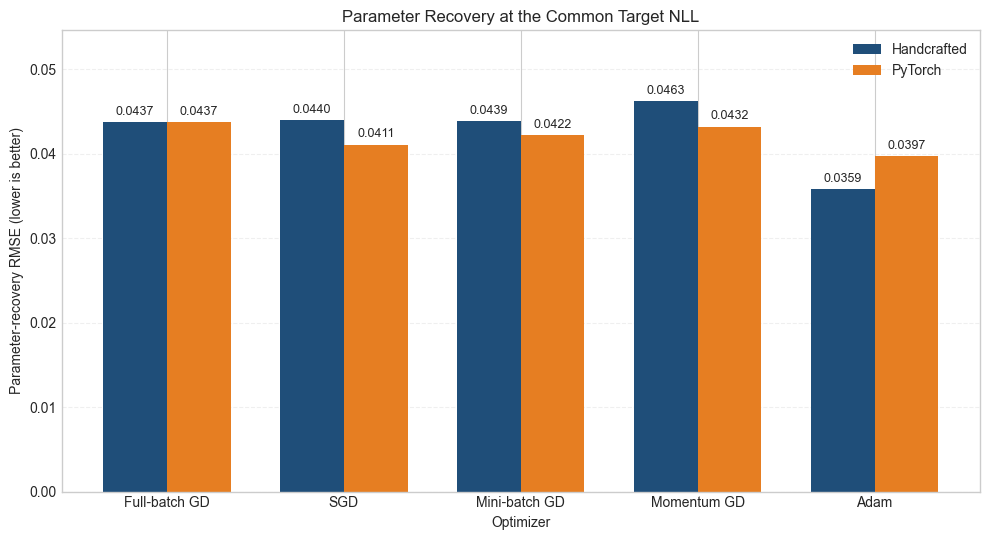

In [54]:
# Compare parameter-recovery RMSE across both implementations.

rmse_plot_data = (
    combined_comparison_table
    .pivot(
        index="Optimizer",
        columns="Implementation",
        values="Recovery RMSE",
    )
    .reindex(optimizer_order)
)

x_positions = np.arange(len(optimizer_order))
bar_width = 0.36

figure, axis = plt.subplots(figsize=(10, 5.5))

handcrafted_bars = axis.bar(
    x_positions - bar_width / 2,
    rmse_plot_data["Handcrafted"],
    width=bar_width,
    color="#1F4E79",
    label="Handcrafted",
)

pytorch_bars = axis.bar(
    x_positions + bar_width / 2,
    rmse_plot_data["PyTorch"],
    width=bar_width,
    color="#E67E22",
    label="PyTorch",
)

axis.bar_label(
    handcrafted_bars,
    labels=[
        f"{value:.4f}"
        for value in rmse_plot_data["Handcrafted"]
    ],
    padding=3,
    fontsize=9,
)

axis.bar_label(
    pytorch_bars,
    labels=[
        f"{value:.4f}"
        for value in rmse_plot_data["PyTorch"]
    ],
    padding=3,
    fontsize=9,
)

axis.set_xticks(x_positions)
axis.set_xticklabels(optimizer_order)
axis.set_xlabel("Optimizer")
axis.set_ylabel("Parameter-recovery RMSE (lower is better)")
axis.set_title("Parameter Recovery at the Common Target NLL")
axis.legend()
axis.grid(axis="y", linestyle="--", alpha=0.3)
axis.set_ylim(
    0,
    1.18 * max(
        rmse_plot_data["Handcrafted"].max(),
        rmse_plot_data["PyTorch"].max(),
    ),
)

plt.tight_layout()
plt.show()